In [1]:
import pandas as pd

papers = pd.read_csv("bibliography_final_analysis.csv")

print("Papers loaded:", len(papers))
print("Descriptions available:", papers["analysis_text"].notna().sum())

Papers loaded: 3932
Descriptions available: 3932


In [3]:
try:
    import sklearn
    print("scikit-learn is available")
except ImportError:
    print("scikit-learn is not installed")

scikit-learn is available


In [4]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def english_word_share(value):
    words = re.findall(r"[a-z]+", str(value).lower())
    if not words:
        return 0
    return sum(word in ENGLISH_STOP_WORDS for word in words) / len(words)

papers["english_word_share"] = papers["analysis_text"].apply(english_word_share)

print(
    papers.nsmallest(12, "english_word_share")[
        ["source_row", "Title", "english_word_share"]
    ].to_string(index=False, max_colwidth=90)
)

 source_row                                                                                      Title  english_word_share
       3537 Rheuma (be-)greifen“ – ein multimodales Lehrkonzept zur Verbesserung der rheumatologisc...            0.021164
       2121                                       Chirurgisches Training am Simulator: Virtual reality            0.033898
       3919         Emotionale virtuelle Charaktere für die Lehre in der Kinder- und Jugendpsychiatrie            0.033898
       1797       Der „Surgical Track“ – innovative Ansätze gegen den Nachwuchsmangel in der Chirurgie            0.042763
       3763                          Digitale Kompetenzen in der Rhythmologie: Training und Ausbildung            0.044776
       2476 The use of virtual simulation or virtual patients in nursing education: An integrative ...            0.077586
       3427 ABASI (Aprendizaje Basado en Simulación): un enfoque integral para el entrenamiento en ...            0.083969
       4909 Pote

In [5]:
print("Records with English-word share below 0.15:",
      (papers["english_word_share"] < 0.15).sum())

row = papers.loc[papers["source_row"] == 2476].iloc[0]
print("Row 2476 description:", row["analysis_text"][:700])

Records with English-word share below 0.15: 16
Row 2476 description: Uvod: Epidemija covida-19 je omejila praktično usposabljanje študentov zdravstvene nege. V zdravstveni negi simulacije niso novost, razmeroma novo področje izobraževanja pa so virtualne simulacije ali virtualni pacienti. Namen pregleda je bil preučiti najnovejše empirične ugotovitve o učinkovitosti oziroma uspešnosti uporabe virtualnih simulacij ali virtualnih pacientov pri študiju zdravstvene nege po svetu. Metode: Pregledani so bili znanstveni članki, objavljeni med letoma 2016 in 2021 v bibliografskih bazah CINAHL, MEDLINE, ERIC ter v kataložno-bibliografski bazi podatkov COBIB. Proučevani so bili članki, ki so obravnavali študente zdravstvene nege, pri katerih sta bila virtualna simulaci


In [6]:
print(
    papers.loc[
        papers["english_word_share"] < 0.15,
        ["source_row", "Title", "english_word_share"]
    ].sort_values("english_word_share")
     .to_string(index=False, max_colwidth=100)
)

 source_row                                                                                                Title  english_word_share
       3537 Rheuma (be-)greifen“ – ein multimodales Lehrkonzept zur Verbesserung der rheumatologischen Lehre ...            0.021164
       2121                                                 Chirurgisches Training am Simulator: Virtual reality            0.033898
       3919                   Emotionale virtuelle Charaktere für die Lehre in der Kinder- und Jugendpsychiatrie            0.033898
       1797                 Der „Surgical Track“ – innovative Ansätze gegen den Nachwuchsmangel in der Chirurgie            0.042763
       3763                                    Digitale Kompetenzen in der Rhythmologie: Training und Ausbildung            0.044776
       2476 The use of virtual simulation or virtual patients in nursing education: An integrative literature...            0.077586
       3427 ABASI (Aprendizaje Basado en Simulación): un enfoque inte

In [7]:
for _, row in papers[
    papers["source_row"].isin([3247, 1572, 45])
].iterrows():
    print("\nROW:", row["source_row"])
    print("DESCRIPTION:", row["analysis_text"][:500])


ROW: 45
DESCRIPTION: PurposeExtended reality, an umbrella term for virtual, augmented, and mixed reality, is increasingly used in health care education as it requires fewer human and logistical resources and offers reduced costs compared with high-fidelity simulations. Nevertheless, the impact of extended reality on education and training in anesthesiology is largely unknown. We aimed to explore the existing extended reality tools and applications in anesthesiology, identify current knowledge gaps, and highlight fut

ROW: 1572
DESCRIPTION: Van Charles Lansingh,1–5 Stephen Chai,6 Nicoletta Fynn-Thompson,1 Akshay Gopinathan Nair,7,8 Jared J Tuttle9 1HelpMeSee, Jersey City, NJ, USA; 2Instituto Mexicano de Oftalmología, Santiago de Querétaro, Qro, Mexico; 3Department of Public Health Sciences, University of Miami Miller School of Medicine, Miami, FL, USA; 4Department of Ophthalmology and Visual Sciences, John A. Moran Eye Center, University of Utah, Salt Lake City, UT, USA; 5Centro de Inv

In [8]:
for row_id in [1572, 3247]:
    description = papers.loc[
        papers["source_row"] == row_id, "analysis_text"
    ].iloc[0]
    print("\nROW:", row_id, "LENGTH:", len(description))
    print("END:", description[-800:])


ROW: 1572 LENGTH: 966
END: Oftalmología, Santiago de Querétaro, Qro, Mexico; 3Department of Public Health Sciences, University of Miami Miller School of Medicine, Miami, FL, USA; 4Department of Ophthalmology and Visual Sciences, John A. Moran Eye Center, University of Utah, Salt Lake City, UT, USA; 5Centro de Investigación en Salud Poblacional, Instituto Nacional de Salud Pública, Cuernavaca, Morelos, Mexico; 6California University of Science and Medicine, Colton, CA, USA; 7Dr Agarwal’s Group of Eye Hospitals, Mumbai, India; 8HMS Vision Pvt. Ltd., Mumbai, India; 9University of Texas Health Science Center at San Antonio, San Antonio, TX, USACorrespondence: Van Charles Lansingh, HelpMeSee, 1 Evertrust Plaza Suite 308, Jersey City, NJ, 07302, USA, Tel +1 954 684-8179, Fax +1 212 221-7604, Email vancharles@helpmesee.org

ROW: 3247 LENGTH: 368
END: Javed MQ, Arjumand B, Klarkodi SH, Atique S, Abulhamael AM, Zafar MS. Influence of virtual reality simulation (excluding augmented reality) on 

In [9]:
import pandas as pd

model_papers = pd.read_csv("bibliography_model_input.csv")

non_english_rows = [
    3537, 2121, 3919, 1797, 3763, 2476, 1791,
    3427, 4909, 4689, 428, 4019, 4921
]

model_papers = model_papers[
    ~model_papers["source_row"].isin(non_english_rows)
].copy()

print("English-language papers for topic modeling:", len(model_papers))

English-language papers for topic modeling: 3912


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    min_df=10,
    max_df=0.80,
    max_features=12000,
    ngram_range=(1, 2)
)

word_matrix = vectorizer.fit_transform(
    model_papers["analysis_text"].fillna("")
)

print("Papers:", word_matrix.shape[0])
print("Words and phrases:", word_matrix.shape[1])

Papers: 3912
Words and phrases: 8968


In [11]:
from sklearn.decomposition import NMF

topic_model = NMF(
    n_components=10,
    init="nndsvda",
    random_state=42,
    max_iter=400
)

paper_topics = topic_model.fit_transform(word_matrix)

terms = vectorizer.get_feature_names_out()

for topic_number, weights in enumerate(topic_model.components_, start=1):
    top = weights.argsort()[-12:][::-1]
    print(f"Topic {topic_number}: " + ", ".join(terms[top]))

Topic 1: nursing, simulation, students, nursing students, learning, nursing education, clinical, virtual, education, virtual reality, practice, care
Topic 2: ar, augmented reality, augmented, reality ar, ar vr, applications, vr ar, ar technology, technology, surgical, ar based, technologies
Topic 3: surgical, training, simulator, surgery, laparoscopic, simulation, surgeons, simulators, skills, surgical training, performance, virtual
Topic 4: group, control, control group, groups, experimental, test, intervention, scores, experimental group, students, study, knowledge
Topic 5: vr, training, reality vr, vr training, vr simulation, medical, vr based, immersive, participants, vr technology, immersive vr, study
Topic 6: studies, review, systematic, meta, articles, included, search, education, systematic review, literature, outcomes, reviews
Topic 7: dental, dental education, haptic, dental students, students, dentistry, preclinical, simulator, education, cavity, virtual, teeth
Topic 8: anat

In [12]:
for topic_index in range(10):
    top_papers = paper_topics[:, topic_index].argsort()[-3:][::-1]
    print(f"\nTOPIC {topic_index + 1}")
    for position in top_papers:
        row = model_papers.iloc[position]
        print(row["source_row"], "|", str(row["Title"])[:110])


TOPIC 1
4697 | Norwegian nursing students’ evaluation of vSim® for Nursing
2766 | Unpacking how virtual reality stimulates learning through nursing students’ experiences: a qualitative study
2607 | Impact of Virtual Reality Mental Health Nursing Simulation on Nursing Students’ Competence

TOPIC 2
811 | Systematic review and meta-analysis of augmented reality in medicine, retail, and games
871 | The Psychometrics of Cybersickness in Augmented Reality
501 | Augmented reality in medical education: students' experiences and learning outcomes

TOPIC 3
1438 | The role of virtual reality simulation in surgical training in the light of COVID-19 pandemic: Visual spatial 
1141 | The role of virtual reality simulation in surgical training in the light of COVID-19 pandemic: Visual spatial 
4894 | The cutting-edge training modalities and educational platforms for accredited surgical training: A systematic 

TOPIC 4
2095 | The effect of mobile augmented reality application developed for injections 

In [13]:
check_rows = [811, 871, 788, 1159, 492, 2509, 340]

for _, row in working[
    working["source_row"].isin(check_rows)
].iterrows():
    print("\nROW:", row["source_row"])
    print("TITLE:", row["Title"])
    print("DESCRIPTION:", str(row["Description"])[:420])

NameError: name 'working' is not defined

In [14]:
check_rows = [811, 871, 788, 1159, 492, 2509, 340]

for _, row in model_papers[
    model_papers["source_row"].isin(check_rows)
].iterrows():
    print("\nROW:", row["source_row"])
    print("TITLE:", row["Title"])
    print("DESCRIPTION:", str(row["Description"])[:420])


ROW: 340
TITLE: Metaverse: Healthcare’s next frontier
DESCRIPTION: Background: As we are making sense of adding the realities and AI, a newer concept has emerged based on the capabilities being realized through AR, VR and AI, and is taking the world by storm. What is a Metaverse: The evolution of the latest frontier of the Internet is defined and described. Four Facets of the Metaverse: Data, information, and knowledge, people, IoT, and IoE are explored in relation to the metaverse.

ROW: 492
TITLE: Mapping the Evolution of Metaverse Research in Business Domains: A Systematic Literature Review and Future Research Directions
DESCRIPTION: In an increasingly digital world, the metaverse offers new opportunities and presents novel challenges for business applications. With growing interest in its applications in various business sectors such as tourism, healthcare, education, and marketing due to the rich user experiences it can provide, the metaverse has begun to gather increasing resear

In [15]:
off_topic_rows = [340, 492, 788, 811, 871, 1159, 2509]

working["model_input"] = (
    working["final_analysis"]
    & ~working["text_quality_exclude"]
    & ~working["source_row"].isin(off_topic_rows)
)

working.to_csv("bibliography_working.csv", index=False, encoding="utf-8-sig")

working.loc[working["model_input"]].to_csv(
    "bibliography_model_input.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Revised papers ready for analysis:",
      working["model_input"].sum())

NameError: name 'working' is not defined

In [16]:
working = pd.read_csv("bibliography_working.csv")

off_topic_rows = [340, 492, 788, 811, 871, 1159, 2509]
working["off_topic_after_model_review"] = working["source_row"].isin(
    off_topic_rows
)

working["model_input"] = (
    working["final_analysis"]
    & ~working["text_quality_exclude"]
    & ~working["off_topic_after_model_review"]
)

working.to_csv("bibliography_working.csv", index=False, encoding="utf-8-sig")
working.loc[working["model_input"]].to_csv(
    "bibliography_model_input.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Revised papers ready for analysis:",
      working["model_input"].sum())

Revised papers ready for analysis: 3918


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF

model_papers = pd.read_csv("bibliography_model_input.csv")
model_papers = model_papers[
    ~model_papers["source_row"].isin(non_english_rows)
].copy()

common_words = {
    "virtual", "reality", "vr", "ar", "xr", "mr",
    "augmented", "extended", "mixed",
    "study", "studies", "research", "review", "systematic",
    "literature", "article", "articles", "results", "methods",
    "background", "conclusion", "included"
}

vectorizer = TfidfVectorizer(
    stop_words=list(ENGLISH_STOP_WORDS.union(common_words)),
    min_df=10,
    max_df=0.80,
    max_features=12000,
    ngram_range=(1, 2)
)

word_matrix = vectorizer.fit_transform(model_papers["analysis_text"].fillna(""))

topic_model = NMF(n_components=12, init="nndsvda",
                  random_state=42, max_iter=400)
paper_topics = topic_model.fit_transform(word_matrix)

terms = vectorizer.get_feature_names_out()
print("Papers modeled:", len(model_papers))
for number, weights in enumerate(topic_model.components_, start=1):
    top = weights.argsort()[-10:][::-1]
    print(f"Topic {number}: " + ", ".join(terms[top]))

Papers modeled: 3905
Topic 1: medical, education, medical education, health, technology, healthcare, technologies, care, training, applications
Topic 2: simulator, laparoscopic, training, performance, tasks, task, validity, skills, residents, time
Topic 3: group, control, control group, groups, experimental, intervention, experimental group, test, training, scores
Topic 4: 3d, anatomy, models, anatomical, printed, visualization, structures, dimensional, 3d printed, model
Topic 5: dental, dental education, haptic, dental students, students, dentistry, preclinical, education, cavity, teeth
Topic 6: meta, outcomes, meta analysis, evidence, reviews, search, trials, cochrane, analysis, pubmed
Topic 7: surgical, surgery, training, surgical training, surgeons, simulators, surgical education, planning, trainees, procedures
Topic 8: metaverse, digital, healthcare, metaverse based, applications, metaverse technologies, use metaverse, metaverse applications, potential, technologies
Topic 9: nursi

In [18]:
for topic_index in range(12):
    top_papers = paper_topics[:, topic_index].argsort()[-3:][::-1]
    print(f"\nTOPIC {topic_index + 1}")
    for position in top_papers:
        row = model_papers.iloc[position]
        print(row["source_row"], "|", str(row["Title"])[:105])


TOPIC 1
3490 | Looking Back on Digital Medical Education Over the Last 25 Years and Looking to the Future: Narrative Rev
3561 | Looking Backon Digital Medical Education Overthe Last25Years and Looking to the Future: Narrative Review
33 | From static web to metaverse: reinventing medical education in the post-pandemic era

TOPIC 2
3934 | Virtual Reality Laparoscopic Simulator as an Aid in Surgical Resident Education: Two Years' Experience
2695 | Comparison of laparoscopic surgical skills acquired on a virtual reality simulator and a box trainer: an 
2736 | Face, content, and construct validity of the virtual immersive operating room simulator for training lapa

TOPIC 3
4520 | Immersive virtual reality simulation training for cesarean section: a randomized controlled trial
3133 | The Effectiveness of Virtual Reality-Based Multidrug-Resistant Organisms Infection Control Education for 
4185 | Effectiveness of a scenario-based gamified virtual reality training on nurses’ basic life support

In [19]:
extra_words = {
    "medical", "education", "health", "healthcare",
    "technology", "technologies", "group", "groups",
    "control", "experimental", "intervention",
    "meta", "analysis", "search", "pubmed", "cochrane"
}

focused_vectorizer = TfidfVectorizer(
    stop_words=list(ENGLISH_STOP_WORDS.union(common_words, extra_words)),
    min_df=10,
    max_df=0.80,
    max_features=12000,
    ngram_range=(1, 2)
)

focused_matrix = focused_vectorizer.fit_transform(
    model_papers["analysis_text"].fillna("")
)

focused_model = NMF(
    n_components=10, init="nndsvda", random_state=42, max_iter=400
)
focused_scores = focused_model.fit_transform(focused_matrix)
focused_terms = focused_vectorizer.get_feature_names_out()

for number, weights in enumerate(focused_model.components_, start=1):
    top = weights.argsort()[-10:][::-1]
    print(f"Topic {number}: " + ", ".join(focused_terms[top]))

Topic 1: simulation, training, clinical, based, patient, care, simulation based, immersive, high, scenarios
Topic 2: simulator, laparoscopic, training, performance, task, skills, tasks, validity, residents, time
Topic 3: surgical, surgery, training, surgical training, surgeons, simulators, planning, procedures, trainees, robotic
Topic 4: 3d, anatomy, models, anatomical, visualization, structures, dimensional, printed, model, 3d printed
Topic 5: dental, haptic, dental students, students, dentistry, preclinical, cavity, teeth, training, simulator
Topic 6: outcomes, evidence, reviews, databases, scoping, science, quality, criteria, web, published
Topic 7: metaverse, digital, applications, potential, future, metaverse based, medicine, world, social, challenges
Topic 8: nursing, nursing students, students, learning, clinical, ivr, practice, undergraduate nursing, program, experiences
Topic 9: ai, intelligence, artificial intelligence, artificial, intelligence ai, learning, personalized, int

In [20]:
model_papers["topic_number"] = focused_scores.argmax(axis=1) + 1
model_papers["topic_strength"] = focused_scores.max(axis=1)

model_papers.to_csv(
    "topic_assignments_draft.csv",
    index=False,
    encoding="utf-8-sig"
)

for topic_number in range(1, 11):
    count = (model_papers["topic_number"] == topic_number).sum()
    top_positions = focused_scores[:, topic_number - 1].argsort()[-2:][::-1]

    print(f"\nTOPIC {topic_number}: {count} papers")
    for position in top_positions:
        row = model_papers.iloc[position]
        print(row["source_row"], "|", str(row["Title"])[:105])


TOPIC 1: 339 papers
1060 | The 2024 French guidelines for scenario design in simulation-based education: manikin-based immersive sim
2831 | Striving for Better Medical Education: the Simulation Approach

TOPIC 2: 622 papers
2695 | Comparison of laparoscopic surgical skills acquired on a virtual reality simulator and a box trainer: an 
3934 | Virtual Reality Laparoscopic Simulator as an Aid in Surgical Resident Education: Two Years' Experience

TOPIC 3: 430 papers
4894 | The cutting-edge training modalities and educational platforms for accredited surgical training: A system
1873 | Virtual reality headset versus traditional training in orthopedic surgery: A comparative study on real su

TOPIC 4: 415 papers
867 | Virtual and augmented reality systems and three-dimensional printing of the renal model—novel trends to g
3940 | Three-Dimensional Immersive Photorealistic Layered Dissection of Superficial and Deep Back Muscles: Anato

TOPIC 5: 221 papers
326 | Effectiveness of Virtual Reality

In [21]:
try:
    from wordcloud import WordCloud
    print("wordcloud is available")
except ImportError:
    print("wordcloud is not installed")

wordcloud is not installed


In [22]:
try:
    import matplotlib.pyplot as plt
    print("matplotlib is available")
except ImportError:
    print("matplotlib is not installed")

Matplotlib is building the font cache; this may take a moment.


matplotlib is available


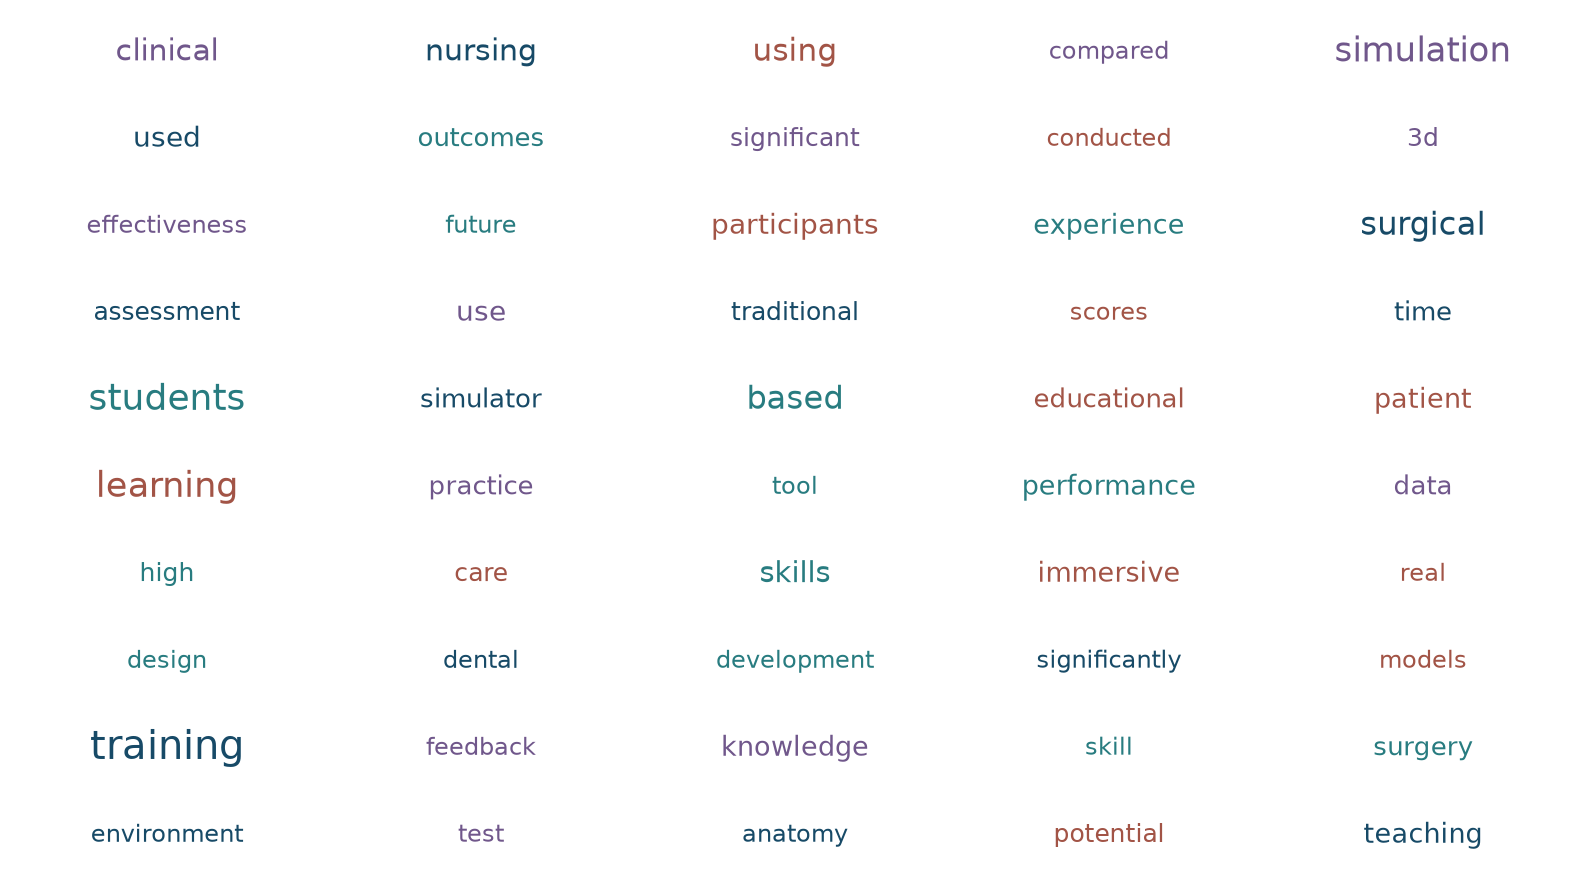

Saved word_cloud.png


In [23]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

cloud_vectorizer = CountVectorizer(
    stop_words=list(ENGLISH_STOP_WORDS.union(common_words, extra_words)),
    min_df=10,
    max_features=50
)

cloud_matrix = cloud_vectorizer.fit_transform(
    model_papers["analysis_text"].fillna("")
)

words = cloud_vectorizer.get_feature_names_out()
counts = np.asarray(cloud_matrix.sum(axis=0)).ravel()
order = counts.argsort()[::-1]

rng = np.random.default_rng(42)
positions = rng.permutation(50)

fig, ax = plt.subplots(figsize=(16, 9))
colors = ["#174a67", "#287c80", "#a25446", "#70578b"]

for rank, index in enumerate(order):
    cell = positions[rank]
    x = cell % 5 + 0.5
    y = cell // 5 + 0.5
    size = 11 + 18 * (counts[index] / counts[order[0]]) ** 0.5

    ax.text(x, y, words[index], ha="center", va="center",
            fontsize=size, color=colors[rank % len(colors)])

ax.set(xlim=(0, 5), ylim=(0, 10))
ax.axis("off")
fig.tight_layout()
fig.savefig("word_cloud.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved word_cloud.png")

In [24]:
import pandas as pd

model_papers = pd.read_csv("sentiment_scores_exploratory.csv")
print("Analysis records restored:", len(model_papers))

Analysis records restored: 3905


In [25]:
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

model_papers = pd.read_csv("topic_assignments_draft.csv")
analyzer = SentimentIntensityAnalyzer()

sentiment = model_papers["analysis_text"].fillna("").apply(
    analyzer.polarity_scores
)

model_papers["sentiment_score"] = sentiment.apply(
    lambda result: result["compound"]
)
model_papers["tone_balance"] = sentiment.apply(
    lambda result: result["pos"] - result["neg"]
)

model_papers.to_csv(
    "sentiment_scores_exploratory.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Papers scored and saved:", len(model_papers))

Papers scored and saved: 3905


In [26]:
model_papers["text_length"] = model_papers["analysis_text"].str.len()

length_groups = pd.qcut(
    model_papers["text_length"], 4,
    labels=["shortest", "short", "long", "longest"]
)

print(
    model_papers.groupby(length_groups, observed=True)["tone_balance"]
    .agg(["count", "median"])
    .round(3)
)

             count  median
text_length               
shortest       977   0.066
short          977   0.065
long           975   0.071
longest        976   0.066


In [27]:
tone_by_topic = (
    model_papers.groupby("topic_number")["tone_balance"]
    .agg(papers="count", median_tone="median")
    .reset_index()
    .round(3)
)

tone_by_topic.to_csv(
    "tone_by_topic.csv", index=False, encoding="utf-8-sig"
)

print(tone_by_topic.to_string(index=False))

 topic_number  papers  median_tone
            1     339        0.067
            2     622        0.046
            3     430        0.068
            4     415        0.071
            5     221        0.061
            6     456        0.057
            7     156        0.097
            8     401        0.086
            9     190        0.103
           10     675        0.075


In [28]:
for topic_number in [2, 9]:
    print(f"\nTOPIC {topic_number}")
    sample = model_papers[
        model_papers["topic_number"] == topic_number
    ].sample(4, random_state=42)

    for _, row in sample.iterrows():
        print("\n", row["source_row"], "|", row["Title"])
        print("END:", str(row["analysis_text"])[-350:])


TOPIC 2

 2723 | Randomized controlled trial investigating the effect of music on the virtual reality laparoscopic learning performance of novice surgeons
END: ) and total task time ( p = 0.065) showed a trend toward improvement when participants considered the music pleasant rather than unpleasant. Conclusions Music in the operating theater may have a distracting effect on novice surgeons performing new tasks. Surgical trainers should consider categorically switching off music during teaching procedures.

 3719 | Virtual environments for medical training: graphical and haptic simulation of laparoscopic common bile duct exploration
END: ted deformations are displayed on the computer screen and the reaction forces are fed back to the user through the force feedback devices. A hybrid modeling approach was developed to simulate the real-time visual and haptic interactions that take place between the forceps and the catheter, as well as the duct; and between the catheter and the duct.

 2

In [29]:
review_pattern = (
    r"\breview\b|meta.analysis|scoping|bibliometric|"
    r"perspective|future directions|trends analysis"
)

model_papers["review_title"] = model_papers["Title"].fillna(
    ""
).str.contains(review_pattern, case=False, regex=True)

for topic_number in [2, 9]:
    group = model_papers[model_papers["topic_number"] == topic_number]
    print(
        "Topic", topic_number,
        "| papers:", len(group),
        "| review-like titles:", group["review_title"].sum(),
        "| percent:", round(group["review_title"].mean() * 100, 1)
    )

Topic 2 | papers: 622 | review-like titles: 32 | percent: 5.1
Topic 9 | papers: 190 | review-like titles: 70 | percent: 36.8


In [30]:
print(
    model_papers[
        model_papers["topic_number"].isin([2, 9])
    ].groupby(["topic_number", "review_title"])["tone_balance"]
     .agg(["count", "median"])
     .round(3)
)

                           count  median
topic_number review_title               
2            False           590   0.046
             True             32   0.051
9            False           120   0.107
             True             70   0.096


## End of exploratory sentiment analysis

VADER scored 3,905 descriptions. Whole-description scores increased with text length, so I used positive-word share minus negative-word share for a descriptive check. The measure describes abstract wording, not training effectiveness. Sentiment is not used to support the theory-building claims below.

## Topic interpretation begins

In [32]:
for topic_number in range(1, 6):
    print(f"\nTOPIC {topic_number}")
    sample = model_papers[
        model_papers["topic_number"] == topic_number
    ].sample(4, random_state=17)

    for _, row in sample.iterrows():
        print(row["source_row"], "|", str(row["Title"])[:110])


TOPIC 1
3764 | 63 Development of a virtual reality educational application for peritoneal dialysis training
4443 | Design of a Virtual Reality Interactive Training System for Public Health Emergency Preparedness for Major Eme
3395 | SC2 Incorporating virtual reality simulations into undergraduate nursing curriculum
3837 | Factors Influencing Virtual Reality Sickness in Emergency Simulation Training

TOPIC 2
4559 | Assessment of orthopaedic surgery residents' skill progression using a non-immersive virtual reality hip arthr
973 | Does mental imagery make a difference in virtual reality simulation training? Results of a randomized controll
3694 | Using Virtual Reality to teach ultrasound-guided needling skills for regional anaesthesia: A randomised contro
2599 | Effect of real-time virtual reality-based teaching cues on learning needle passing for robot-assisted minimall

TOPIC 3
3563 | Quantitative metrics for evaluating surgical dexterity using virtual reality simulations
4213 | Virtu

In [33]:
for topic_number in range(6, 11):
    print(f"\nTOPIC {topic_number}")
    sample = model_papers[
        model_papers["topic_number"] == topic_number
    ].sample(4, random_state=17)

    for _, row in sample.iterrows():
        print(row["source_row"], "|", str(row["Title"])[:110])


TOPIC 6
2576 | AUGMENTED REALITY ESCAPE ROOMS AS NEUROCOGNITIVE TRAINING ENVIRONMENTS
4962 | Scoping Review: The Effectiveness of Interprofessional Virtual Reality Simulation
3999 | Application of Virtual Reality Technology in Disaster Medicine
3912 | Emerging Utility of Virtual Reality as a Multidisciplinary Tool in Clinical Medicine

TOPIC 7
134 | The surgical metaverse
1107 | 940 The Metaverse as a Potential Solution for the Delivery of Global Health Education
4927 | Enhancing learning motivation and academic achievement in nursing students through metaverse‐based learning: A
482 | P‐2.8: Metaverse: Origin, Current Applications and Prospects for Future Development

TOPIC 8
1076 | Development of disaster nursing education and training programs in the past 20 years (2000–2019): A systematic
1630 | Virtual reality in nursing education 3D intravenous catheterization E-learning: A randomized controlled trial
1544 | Improving nursing education through an AI-enhanced mixed reality trainin

In [1]:
import pandas as pd

papers = pd.read_csv("topic_assignments_draft.csv")

print("Papers:", len(papers))
print("Topics:", sorted(papers["topic_number"].unique()))

Papers: 3905
Topics: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [2]:
topic = papers[papers["topic_number"] == 1]

strongest = topic.nlargest(4, "topic_strength")
varied = topic.sample(4, random_state=27)

print("STRONGEST MATCHES")
print(strongest[["source_row", "Title"]]
      .to_string(index=False, max_colwidth=110))

print("\nRANDOM SAMPLE")
print(varied[["source_row", "Title"]]
      .to_string(index=False, max_colwidth=110))

STRONGEST MATCHES
 source_row                                                                                                          Title
       1060 The 2024 French guidelines for scenario design in simulation-based education: manikin-based immersive simul...
       2831                                                 Striving for Better Medical Education: the Simulation Approach
       1113 Assessing the Financial Sustainability of High-Fidelity and Virtual Reality Simulation for Nursing Educatio...
         42                               Nursing Simulation 3.0: Contemporary issues in transitioning to extended reality

RANDOM SAMPLE
 source_row                                                                                                          Title
       3033 Enhancing Disaster Preparedness and Community Safety Through Virtual Simulation: A Scoping Review in Underg...
       3954 Healing Health Care Disparities: Development and Pilot Testing of a Virtual Reality Implicit B

In [3]:
for number in [2, 3]:
    group = papers[papers["topic_number"] == number]

    print(f"\nTOPIC {number} — STRONGEST")
    print(group.nlargest(3, "topic_strength")[["source_row", "Title"]]
          .to_string(index=False, max_colwidth=110))

    print(f"TOPIC {number} — RANDOM")
    print(group.sample(3, random_state=27)[["source_row", "Title"]]
          .to_string(index=False, max_colwidth=110))


TOPIC 2 — STRONGEST
 source_row                                                                                                          Title
       2695 Comparison of laparoscopic surgical skills acquired on a virtual reality simulator and a box trainer: an an...
       3934         Virtual Reality Laparoscopic Simulator as an Aid in Surgical Resident Education: Two Years' Experience
       2736 Face, content, and construct validity of the virtual immersive operating room simulator for training laparo...
TOPIC 2 — RANDOM
 source_row                                                                                                          Title
       3348 Virtual Reality Simulator versus Conventional Advanced Life Support Training for Cardiopulmonary Resuscitat...
       3296                                    Developing Effective Automated Feedback in Temporal Bone Surgery Simulation
        815                        Telestration with augmented reality improves surgical performance 

In [4]:
for number in [4, 5]:
    group = papers[papers["topic_number"] == number]

    print(f"\nTOPIC {number} — STRONGEST")
    print(group.nlargest(3, "topic_strength")[["source_row", "Title"]]
          .to_string(index=False, max_colwidth=110))

    print(f"TOPIC {number} — RANDOM")
    print(group.sample(3, random_state=27)[["source_row", "Title"]]
          .to_string(index=False, max_colwidth=110))


TOPIC 4 — STRONGEST
 source_row                                                                                                          Title
        867 Virtual and augmented reality systems and three-dimensional printing of the renal model—novel trends to gui...
       3940 Three-Dimensional Immersive Photorealistic Layered Dissection of Superficial and Deep Back Muscles: Anatomi...
       1687                        Creating 3D models from Radiologic Images for Virtual Reality Medical Education Modules
TOPIC 4 — RANDOM
 source_row                                                                                                          Title
       4283 The anatomical wax collection at the University of Bologna: bridging the gap between tradition and scientif...
        490                       Mixed-Reality Visualization of Impacted Teeth: A Survey of Undergraduate Dental Students
       4441                                Haptic‐based virtual reality simulator for lateral ventric

In [5]:
for number in [6, 7]:
    group = papers[papers["topic_number"] == number]

    print(f"\nTOPIC {number} — STRONGEST")
    print(group.nlargest(3, "topic_strength")[["source_row", "Title"]]
          .to_string(index=False, max_colwidth=110))

    print(f"TOPIC {number} — RANDOM")
    print(group.sample(3, random_state=27)[["source_row", "Title"]]
          .to_string(index=False, max_colwidth=110))


TOPIC 6 — STRONGEST
 source_row                                                                                                          Title
        412    Virtual, Augmented, Mixed, and Immersive Technologies for Prenatal and Childbirth Education: Scoping Review
        171 Effectiveness of simulation technologies and virtual reality in enhancing empathy in health care education:...
       3662 Distance-Based Educational Interventions for Empathy and Compassionate Care: A Systematic Review of Interna...
TOPIC 6 — RANDOM
 source_row                                                                                                          Title
        646                                    Virtual reality simulations in nurse education: A systematic mapping review
       2932 Immersive insights: A qualitative systematic review and thematic synthesis of views, experiences, health an...
        398 Adopting augmented reality and virtual reality in medical education in resource-limited s

In [6]:
for number in [8, 9]:
    group = papers[papers["topic_number"] == number]

    print(f"\nTOPIC {number} — STRONGEST")
    print(group.nlargest(3, "topic_strength")[["source_row", "Title"]]
          .to_string(index=False, max_colwidth=110))

    print(f"TOPIC {number} — RANDOM")
    print(group.sample(3, random_state=27)[["source_row", "Title"]]
          .to_string(index=False, max_colwidth=110))


TOPIC 8 — STRONGEST
 source_row                                                                                                        Title
       4697                                                  Norwegian nursing students’ evaluation of vSim® for Nursing
       2766 Unpacking how virtual reality stimulates learning through nursing students’ experiences: a qualitative study
       2607                   Impact of Virtual Reality Mental Health Nursing Simulation on Nursing Students’ Competence
TOPIC 8 — RANDOM
 source_row                                                                                                          Title
       4397 Study on the Integrated Teaching-Learning-Evaluation Model of Virtual Simulation Technology in Nursing Skil...
        547 Usability Evaluation of the Preoperative ISBAR (Identification, Situation, Background, Assessment, and Reco...
       3015                             Using Virtual Reality in Mental Health Nursing to Improve Behavioral 

In [7]:
group = papers[papers["topic_number"] == 10]

print("TOPIC 10 — STRONGEST")
print(group.nlargest(4, "topic_strength")[["source_row", "Title"]]
      .to_string(index=False, max_colwidth=110))

print("\nTOPIC 10 — RANDOM")
print(group.sample(4, random_state=27)[["source_row", "Title"]]
      .to_string(index=False, max_colwidth=110))

TOPIC 10 — STRONGEST
 source_row                                                                                                          Title
       3042                         Is Augmented Reality the New Way for Teaching and Learning Veterinary Cardiac Anatomy?
       4012 Virtual Reality simulation and Video Lecture are Equally Effective in Abscess Incision Training: A Multicen...
       4853             Virtual reality in midwifery education: A mixed methods study to assess learning and understanding
       4661    629 Virtual Reality Meets ENT: a Pilot Randomised Control Trial for Teaching Peritonsillar Abscess Drainage

TOPIC 10 — RANDOM
 source_row                                                                                                          Title
       1679                                                    AnemiaAR: a serious game to support teaching of haematology
       3899                                             Impact of Virtual Reality on Pharmacology E

In [8]:
topic_labels = {
    1: "Design, implementation, and evaluation of clinical simulation",
    2: "Task-based simulation training and performance feedback",
    3: "VR adoption in surgical education",
    4: "3D models and spatial visualization for anatomy or procedure",
    5: "Dental VR and haptic simulation",
    6: "Evidence syntheses on immersive health education",
    7: "Metaverse applications, adoption and proposed uses",
    8: "Virtual simulation in nursing education",
    9: "AI integration in medical education and immersive technologies",
    10: "Instructional comparisons and learning outcomes",
}

topic_table = (
    papers.groupby("topic_number")
    .size()
    .rename("papers")
    .reset_index()
)

topic_table["provisional_label"] = topic_table["topic_number"].map(topic_labels)
topic_table.to_csv("topic_labels_draft.csv", index=False, encoding="utf-8-sig")

print(topic_table.to_string(index=False))

 topic_number  papers                                              provisional_label
            1     339  Design, implementation, and evaluation of clinical simulation
            2     622        Task-based simulation training and performance feedback
            3     430                              VR adoption in surgical education
            4     415   3D models and spatial visualization for anatomy or procedure
            5     221                                Dental VR and haptic simulation
            6     456               Evidence syntheses on immersive health education
            7     156             Metaverse applications, adoption and proposed uses
            8     401                        Virtual simulation in nursing education
            9     190 AI integration in medical education and immersive technologies
           10     675                Instructional comparisons and learning outcomes


In [9]:
text = papers["analysis_text"].fillna("")

construct_patterns = {
    "engagement": r"\bengag\w*|\bmotivat\w*",
    "confidence": r"self[- ]efficacy|\bconfiden\w*",
    "performance": r"\bperform\w*|\bcompetenc\w*|\bproficien\w*",
    "transfer": r"\btransfer\w*|real[- ]world",
    "retention": r"\bretention\b|\bretained\b|long[- ]term",
}

for name, pattern in construct_patterns.items():
    papers[name] = text.str.contains(pattern, case=False, regex=True)

mention_rates = (
    papers.groupby("topic_number")[list(construct_patterns)]
    .mean()
    .mul(100)
    .round(1)
)

print(mention_rates.to_string())

              engagement  confidence  performance  transfer  retention
topic_number                                                          
1                   20.1        19.5         41.6       8.3        4.7
2                    6.1         8.5         82.8      15.0        4.0
3                    6.0         8.4         45.8      10.7        4.4
4                   16.1         6.3         36.6      10.1       10.4
5                   14.0        16.3         53.8      10.0        5.4
6                   23.2        19.1         50.0      11.4       18.9
7                   30.8         9.0         26.9       9.0        4.5
8                   31.4        26.2         39.9       7.2        4.7
9                   25.3        13.7         49.5      11.6       15.3
10                  29.2        22.8         40.1       7.1       10.8


In [10]:
both = papers["engagement"] & papers["performance"]

mismatch_words = text.str.contains(
    r"no significant|did not improve|no difference|however|despite",
    case=False, regex=True
)

candidates = papers[both & mismatch_words]

print("Papers mentioning both constructs and a contrast word:",
      len(candidates))
print(candidates[["source_row", "Title", "topic_number"]]
      .sample(min(10, len(candidates)), random_state=42)
      .to_string(index=False, max_colwidth=110))

Papers mentioning both constructs and a contrast word: 161
 source_row                                                                                                          Title  topic_number
       2511 A motivational model‐based virtual reality approach to prompting learners' sense of presence, learning achi...            10
       2607                     Impact of Virtual Reality Mental Health Nursing Simulation on Nursing Students’ Competence             8
       3815                                 Virtual reality breaks for stress reduction among graduate and dental students            10
       1354 Virtual reality in nursing education: Integrating technology, pedagogy, and learning outcomes – A scoping r...             6
       2196 Comparing the effectiveness of immersive virtual simulation and high-fidelity simulations in mechanical ven...             8
        586     Holopatient technology in nursing education: a cross-sectional analysis of student and faculty percepti

In [11]:
check_rows = [2511, 2607, 2196, 586, 2356]

for _, row in papers[
    papers["source_row"].isin(check_rows)
].iterrows():
    print("\nROW:", row["source_row"])
    print("TITLE:", row["Title"])
    print("ENDING:", str(row["analysis_text"])[-850:])


ROW: 586
TITLE: Holopatient technology in nursing education: a cross-sectional analysis of student and faculty perceptions
ENDING: nursing education to enhance clinical reasoning and student engagement. However, differences in perception between students and faculty remain underexplored. Methods A cross-sectional survey was conducted among 126 participants (84 nursing students and 42 faculty members) at a Saudi Arabian nursing college. All participants had prior exposure to Holopatient scenarios, including adult medical-surgical and maternal health cases. A researcher-developed, 20-item Likert-scale questionnaire assessed four domains: perceived effectiveness, overall satisfaction, ease of use, and implementation challenges. Descriptive statistics, chi-square tests, and multiple regression analyses were performed. Results Students rated perceived effectiveness significantly higher (mean [ M ] = 4.2, standard deviation [ SD ] = 0.6) than faculty ( M = 3.8, SD = 0.8; p

ROW: 2196
TITLE:

In [12]:
counterexamples = papers[
    papers["analysis_text"].fillna("").str.contains(
        r"confidence|self.efficacy", case=False, regex=True
    )
    & papers["analysis_text"].fillna("").str.contains(
        r"knowledge|performance|skill", case=False, regex=True
    )
    & papers["analysis_text"].fillna("").str.contains(
        r"no significant difference|not significantly different|"
        r"did not improve|no improvement",
        case=False, regex=True
    )
]

print("Candidates:", len(counterexamples))
print(
    counterexamples[["source_row", "Title"]]
    .sample(min(12, len(counterexamples)), random_state=9)
    .to_string(index=False, max_colwidth=110)
)

Candidates: 30
 source_row                                                                                                          Title
       2106 Anterior cervical discectomy and fusion training with virtual reality: enhance cognition, attitudes, self-e...
        725 Comparative Effectiveness of Mental Health Simulation Techniques in Nursing Education: A Systematic Review ...
       3318 Learning from the learners: Evaluation of augmented reality-based medication administration program for nur...
       1813                                                        Benefits of using virtual reality in cariology teaching
        795 Effectiveness of AI- and VR-based simulation with traditional teaching in healthcare education: A network m...
        698 Effectiveness of virtual and augmented reality for cardiopulmonary resuscitation training: a systematic rev...
       2968               Simulation‐Based Education Versus Traditional Teaching for Nursing Students: A Systematic Review
 

In [13]:
check_rows = [2106, 3318, 1813, 2237, 798, 2708]

for _, row in papers[
    papers["source_row"].isin(check_rows)
].iterrows():
    print("\nROW:", row["source_row"])
    print("TITLE:", row["Title"])
    print("ENDING:", str(row["analysis_text"])[-1000:])


ROW: 798
TITLE: The effects of an immersive 3d interactive video program on improving student nurses' nursing skill competence: A randomized controlled trial study
ENDING: e immersive 3D interactive video program in the intervention group was significantly higher than in the comparison group that watched a regular video (t = 2.302, p = 0.026). The findings of this study showed that both immersive 3D interactive video program and regular demonstration video could improve nursing students' learning outcomes. The higher satisfaction score in the intervention group indicates that learning through immersive 3D interactive video is acceptable and satisfactory. This study provides useful information for nursing faculty members for designing and developing teaching methods for the acquisition of nursing skills. It can also serve as a reference for further studies relating to AR, VR, or immersive learning materials. Student nurses' skill knowledge improved after immersing in a 3D interactive v

In [14]:
evidence_rows = [2196, 2237, 2356, 2708, 3318, 1813]

evidence = papers.loc[
    papers["source_row"].isin(evidence_rows),
    ["source_row", "Title", "Creator", "Is Part Of", "permalink"]
].sort_values("source_row")

evidence.to_csv(
    "pattern_evidence_papers.csv",
    index=False,
    encoding="utf-8-sig"
)

print(evidence.to_string(index=False, max_colwidth=65))

 source_row                                                             Title                                                           Creator                                                        Is Part Of                                                         permalink
       1813           Benefits of using virtual reality in cariology teaching               Hamama, Hamdi ; Harrison, Ka Yan ; Murbay, Sukhdeep BMC medical education, 2024-09, Vol.24 (1), p.1051-8, Article ... https://onesearch.uark.edu/permalink/01UARK_INST/uveag8/cdi_ga...
       2196 Comparing the effectiveness of immersive virtual simulation an...                                                       Park, Sunah Clinical simulation in nursing, 2025-08, Vol.105, p.101769, Ar... https://onesearch.uark.edu/permalink/01UARK_INST/uveag8/cdi_el...
       2237 Augmented reality for intramuscular injection training: A clus... Soto-Ruiz, Nelia ; Escalada-Hernández, Paula ; Bujanda-Sainz d... Teaching and learning in nur

In [15]:
import re

mechanism_words = (
    r"feedback|haptic|hands.on|physical|interaction|"
    r"cognitive load|realism|fidelity"
)

for row_id in [2196, 2237, 2356, 3318]:
    row = papers.loc[papers["source_row"] == row_id].iloc[0]
    sentences = re.split(r"(?<=[.!?])\s+", str(row["analysis_text"]))

    matches = [
        sentence for sentence in sentences
        if re.search(mechanism_words, sentence, re.IGNORECASE)
    ]

    print("\nROW:", row_id, "|", row["Title"])
    for sentence in matches[:5]:
        print("-", sentence[:320])


ROW: 2196 | Comparing the effectiveness of immersive virtual simulation and high-fidelity simulations in mechanical ventilator nursing education: A randomized crossover design
- Immersive virtual simulation (IVS) and high-fidelity simulation (HFS) training for mechanical ventilator nursing education are equally effective in improving knowledge.
- A randomized, crossover design study was conducted to compare the effectiveness of immersive virtual simulation (IVS) and high-fidelity simulation (HFS) in mechanical ventilator nursing education.
- These findings suggest that IVS education for mechanical ventilator nursing education for nursing students can serve as an effective hands-on training methodology to enhance critical care nursing competency.

ROW: 2237 | Augmented reality for intramuscular injection training: A cluster randomized controlled trial

ROW: 2356 | Evaluating medical students’ engagement and confidence across three simulation-based education methods: standardized patien

In [16]:
abstracts = papers["analysis_text"].fillna("")

load_clue = abstracts.str.contains(
    r"cognitive load|mental effort|mental workload|"
    r"cognitive burden",
    case=False, regex=True
)

usability_clue = abstracts.str.contains(
    r"usability|ease of use|user.friendly|technical difficult|"
    r"interface",
    case=False, regex=True
)

outcome_clue = abstracts.str.contains(
    r"knowledge|skill|performance|competenc",
    case=False, regex=True
)

mechanism_candidates = papers[
    (load_clue | usability_clue) & outcome_clue
]

print("Papers mentioning a load/usability clue and an outcome:",
      len(mechanism_candidates))
print(
    mechanism_candidates[["source_row", "Title"]]
    .sample(min(12, len(mechanism_candidates)), random_state=27)
    .to_string(index=False, max_colwidth=110)
)

Papers mentioning a load/usability clue and an outcome: 418
 source_row                                                                                                          Title
       2335                                    VR Simulation Leads to Enhanced Procedural Confidence for Surgical Trainees
       4696 Effectiveness of an immersive virtual reality environment on curricular training for complex cognitive skil...
       1395                           Fully immersive virtual reality for skull-base surgery: surgical training and beyond
       4195 A Study of Professional Awareness Using Immersive Virtual Reality: The Responses of General Practitioners t...
        872                          Variability-Adaptive IV insertion training with dual haptic feedback in mixed reality
         35   Setting a research agenda for the use of extended reality in healthcare simulation: an Utstein style meeting
        746                                          Measuring Cognitive Load i

In [17]:
focused_candidates = papers[
    load_clue & usability_clue & outcome_clue
]

print("Focused candidates:", len(focused_candidates))
print(
    focused_candidates[["source_row", "Title"]]
    .to_string(index=False, max_colwidth=110)
)

Focused candidates: 23
 source_row                                                                                                          Title
        104 Human task performance and associated internal states in extended reality: a systematic review of cognitive...
        164                                                                     Extended Reality in Health Care Simulation
        278                      Medical Students’ Experiences With Virtual Reality Simulation Training: Qualitative Study
        288         Scoping review: The use of augmented reality in clinical anatomical education and its assessment tools
        337                   Extended Reality in Health Care Simulation: Current State, Challenges, and Future Directions
        413 Innovations in communication training for medical and nursing students: Virtual reality communication tool ...
        458 Nurses’ Knowledge and Skills After Use of an Augmented Reality App for Advanced Cardiac Life Support Tra

In [19]:
check_rows = [2429, 4629, 802, 458, 3229]

for _, row in papers[
    papers["source_row"].isin(check_rows)
].iterrows():
    print("\nROW:", row["source_row"])
    print("TITLE:", row["Title"])
    print("ENDING:", str(row["analysis_text"])[-1100:])


ROW: 458
TITLE: Nurses’ Knowledge and Skills After Use of an Augmented Reality App for Advanced Cardiac Life Support Training: Randomized Controlled Trial
ENDING: raining course was evaluated. The AR group used a crash cart learning system developed with AR technology, while the control group received traditional lecture-based instruction. Both groups were evaluated immediately after the course. Performance was assessed through learning outcomes related to overall ACLS and crash cart use. The Instructional Materials Motivation Survey, System Usability Scale, and Cognitive Load Theory Questionnaire were also used to assess secondary outcomes in the AR group. Subgroup analyses were performed for nurses with less than 2 years of experience. Results: All 102 nurses completed the course, with 43 nurses in the AR group and 59 nurses in the control group. The AR group outperformed the control group regarding overall ACLS outcomes and crash cart learning outcomes (P=.002; P=.01). The improvem

In [20]:
mechanism_rows = [458, 802, 2429, 3229, 4629]

mechanism_evidence = papers.loc[
    papers["source_row"].isin(mechanism_rows),
    ["source_row", "Title", "Creator", "Is Part Of", "permalink"]
].sort_values("source_row")

mechanism_evidence.to_csv(
    "mechanism_evidence_papers.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved mechanism papers:", len(mechanism_evidence))

Saved mechanism papers: 5


## Provisional pattern and explanation

**Pattern.** Immersive training studies do not show a single kind of learning gain. In the abstracts reviewed, greater confidence and engagement did not always coincide with greater knowledge (row 2196); greater knowledge did not always coincide with better technical skills (row 2237). A VR scene comparison found differences in presence, comprehension, and cognitive load, but not in task performance or factual recall (row 4629).

**Abductive explanation to investigate.** Design choices may direct learners' attention toward some parts of a clinical task while adding demands unrelated to that task. This could help explain why a simulation improves one outcome without improving another. Immersion by itself is an incomplete explanation.

**Checks against this idea.** Headset and screen versions produced comparable outcomes in row 802. Usability was associated with technical-skill scores in row 2429, but that association does not show causation. Row 458 reports better learning outcomes with AR, so added technology can help when its design supports the task.

**What remains unknown.** Most of these abstracts do not test whether cognitive load causes the outcome differences. Comparator choice, prior experience, practice time, and outcome measures may also explain them. The full papers are needed before making stronger claims.

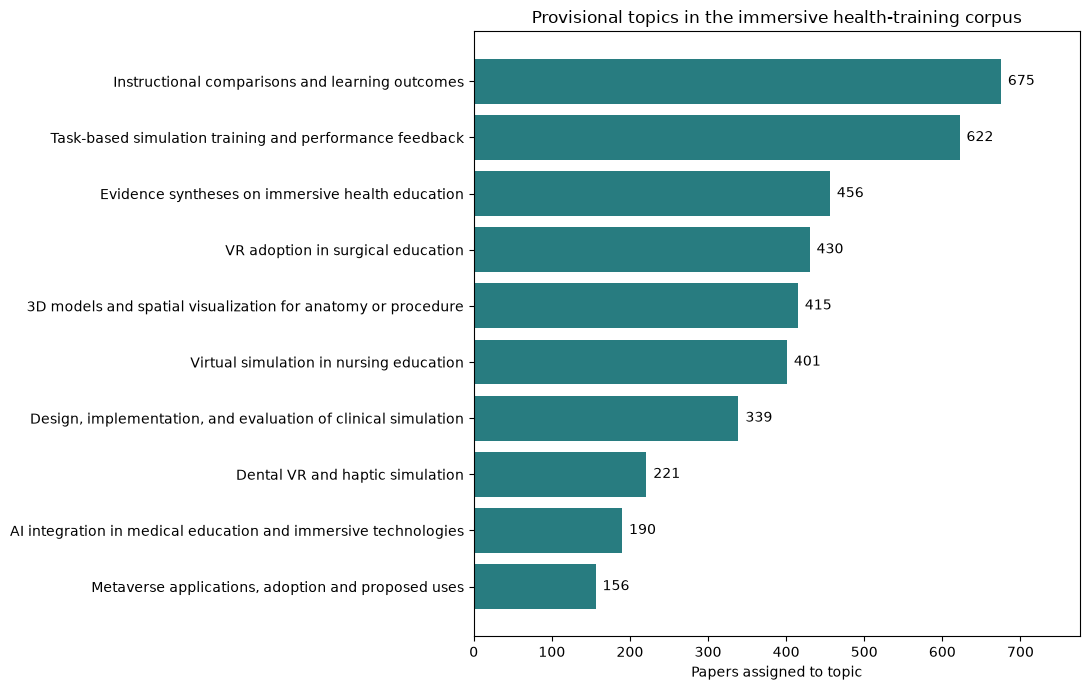

Saved topic_distribution.png


In [21]:
import matplotlib.pyplot as plt
import pandas as pd

labels = pd.read_csv("topic_labels_draft.csv")
labels = labels.sort_values("papers")

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(labels["provisional_label"], labels["papers"],
               color="#287c80")

ax.bar_label(bars, padding=5)
ax.set_xlabel("Papers assigned to topic")
ax.set_title("Provisional topics in the immersive health-training corpus")
ax.set_xlim(0, labels["papers"].max() * 1.15)

fig.tight_layout()
fig.savefig("topic_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved topic_distribution.png")

In [22]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF

common_words = {
    "virtual", "reality", "vr", "ar", "xr", "mr",
    "augmented", "extended", "mixed",
    "study", "studies", "research", "review", "systematic",
    "literature", "article", "articles", "results", "methods",
    "background", "conclusion", "included"
}

extra_words = {
    "medical", "education", "health", "healthcare",
    "technology", "technologies", "group", "groups",
    "control", "experimental", "intervention",
    "meta", "analysis", "search", "pubmed", "cochrane"
}

vectorizer = TfidfVectorizer(
    stop_words=list(ENGLISH_STOP_WORDS.union(common_words, extra_words)),
    min_df=10, max_df=0.80, max_features=12000,
    ngram_range=(1, 2)
)

matrix = vectorizer.fit_transform(papers["analysis_text"].fillna(""))
model = NMF(n_components=10, init="nndsvda",
            random_state=42, max_iter=400)
scores = model.fit_transform(matrix)

agreement = np.mean(
    scores.argmax(axis=1) + 1 == papers["topic_number"].to_numpy()
)

print("Agreement with saved topic assignments:",
      round(agreement * 100, 1), "%")

Agreement with saved topic assignments: 100.0 %


In [23]:
import numpy as np

topic_share = scores / scores.sum(axis=1, keepdims=True)

for threshold in [0.15, 0.25]:
    matches = topic_share >= threshold
    print(f"\nThreshold: {threshold:.0%}")
    print("Papers linked to multiple topics:", (matches.sum(axis=1) > 1).sum())
    for topic_number, count in enumerate(matches.sum(axis=0), start=1):
        print(f"Topic {topic_number}: {count}")


Threshold: 15%
Papers linked to multiple topics: 3250
Topic 1: 1136
Topic 2: 1208
Topic 3: 965
Topic 4: 903
Topic 5: 348
Topic 6: 992
Topic 7: 333
Topic 8: 727
Topic 9: 381
Topic 10: 1580

Threshold: 25%
Papers linked to multiple topics: 1659
Topic 1: 580
Topic 2: 832
Topic 3: 668
Topic 4: 565
Topic 5: 280
Topic 6: 623
Topic 7: 173
Topic 8: 581
Topic 9: 228
Topic 10: 1028


In [24]:
threshold = 0.25
topic_matches = topic_share >= threshold

print("Papers with no topic above 25%:",
      (topic_matches.sum(axis=1) == 0).sum())
print("Papers with one topic above 25%:",
      (topic_matches.sum(axis=1) == 1).sum())
print("Papers with multiple topics above 25%:",
      (topic_matches.sum(axis=1) > 1).sum())

Papers with no topic above 25%: 116
Papers with one topic above 25%: 2130
Papers with multiple topics above 25%: 1659


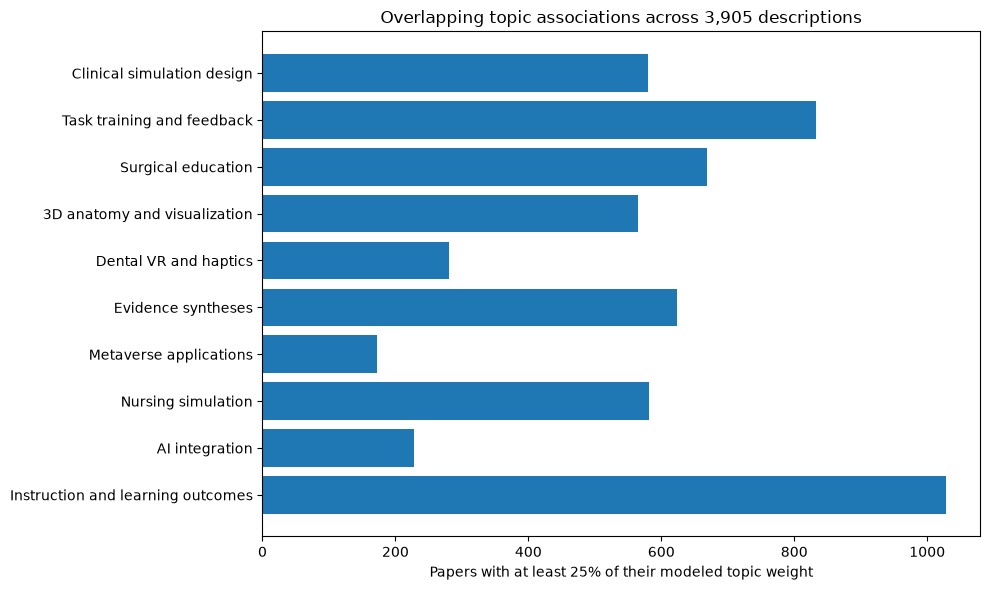

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

short_labels = [
    "Clinical simulation design",
    "Task training and feedback",
    "Surgical education",
    "3D anatomy and visualization",
    "Dental VR and haptics",
    "Evidence syntheses",
    "Metaverse applications",
    "Nursing simulation",
    "AI integration",
    "Instruction and learning outcomes",
]

overlap_counts = pd.DataFrame({
    "topic_number": range(1, 11),
    "topic_label": short_labels,
    "papers_at_25_percent": topic_matches.sum(axis=0)
})

overlap_counts.to_csv("overlapping_topic_counts.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(overlap_counts["topic_label"], overlap_counts["papers_at_25_percent"])
ax.invert_yaxis()
ax.set_xlabel("Papers with at least 25% of their modeled topic weight")
ax.set_title("Overlapping topic associations across 3,905 descriptions")
fig.tight_layout()
fig.savefig("overlapping_topics.png", dpi=200, bbox_inches="tight")
plt.show()